# Corrected repeated stratified cross-validation — Fix 3.3

**Do not use historical 150-row CSVs.** Run from the corrected project root. This notebook performs the **full 5 × 10 outer-fold study** only when explicitly executed; Fix 3.3 sanity checks use `max_folds=1` outside this notebook. Each fold splits into train (50%), probability calibration (10%), conformal calibration (10%), policy tuning (10%), and independent outer test (20%). Threshold and τ are selected on policy tuning; test cost is reported after freezing the policy. All three cost scenarios are evaluated separately. **Curves are tuning-only** and cannot be presented as independent test risk–coverage curves.

In [3]:
import uuid
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from repeated_cv.repeated_cv_runner import repeated_cv_safety_eval, COST_SCENARIOS
from repeated_cv.model_builders import build_rf, build_xgb, build_rusboost

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '_' + uuid.uuid4().hex[:8]
OUTPUT_ROOT = Path('corrected_repeated_cv_results')
RUN_DIR = OUTPUT_ROOT / RUN_ID
assert not RUN_DIR.exists(), 'Run directory already exists; refuse to overwrite'
RUN_DIR.mkdir(parents=True)
print('Experiment:', RUN_ID)
print('Costs (FN, FP, DEF):', COST_SCENARIOS)

Experiment: 20261115T020229777657Z_558a9ffd
Costs (FN, FP, DEF): ((10, 1, 1), (20, 1, 2), (30, 1, 5))


In [4]:
rf_summary, rf_curves = repeated_cv_safety_eval(
    'RandomForest', 'configs/RandomForest/RFtrain.yaml', build_rf,
    experiment_id=RUN_ID, output_root=OUTPUT_ROOT)

RandomForest: outer fold 1/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 170, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 67}
RandomForest: outer fold 2/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 68}
RandomForest: outer fold 3/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positi

In [7]:
xgb_summary, xgb_curves = repeated_cv_safety_eval(
    'XGBoost', 'configs/XGBoost/XGtrain.yaml', build_xgb,
    experiment_id=RUN_ID, output_root=OUTPUT_ROOT)

XGBoost: outer fold 1/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 170, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 67}
XGBoost: outer fold 2/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 68}
XGBoost: outer fold 3/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tunin

In [8]:
rus_summary, rus_curves = repeated_cv_safety_eval(
    'RUSBoost', 'configs/RUSBoost/RUStrain.yaml', build_rusboost,
    experiment_id=RUN_ID, output_root=OUTPUT_ROOT)

RUSBoost: outer fold 1/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 170, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 67}
RUSBoost: outer fold 2/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tuning': 34, 'positive_test': 68}
RUSBoost: outer fold 3/50 completed; partition counts={'n_train': 5000, 'n_probability_calibration': 1000, 'n_conformal_calibration': 1000, 'n_policy_tuning': 1000, 'n_test': 2000}; failures={'positive_train': 169, 'positive_probability_calibration': 34, 'positive_conformal_calibration': 34, 'positive_policy_tu

In [9]:
all_summary = pd.concat([rf_summary, xgb_summary, rus_summary], ignore_index=True)
all_curves = pd.concat([rf_curves, xgb_curves, rus_curves], ignore_index=True)
assert len(all_summary) == 3 * 50 * len(COST_SCENARIOS)
assert (all_summary['partition'] == 'test').all()
assert (all_curves['partition'] == 'policy_tuning').all()
assert (all_summary['run_id'] == RUN_ID).all()
assert (all_curves['run_id'] == RUN_ID).all()
assert set(all_summary['cost_scenario']) == {'10_1_1','20_1_2','30_1_5'}
all_summary.to_csv(RUN_DIR / 'all_models_repeated_cv_summary.csv', index=False)
all_curves.to_csv(RUN_DIR / 'all_models_TUNING_ONLY_curves.csv', index=False)
print('Frozen test rows:', len(all_summary), 'Tuning-only curve rows:', len(all_curves))
display(all_summary.head())

Frozen test rows: 450 Tuning-only curve rows: 45000


,model,run_id,random_seed,fold_seed,fold_number,repeat,fold,threshold,q_alpha,alpha,...,brier_score,log_loss,ece,conformal_coverage,avg_conformal_set_size,ambiguous_rate,empty_set_fraction,singleton_set_fraction,two_label_set_fraction,failure_class_coverage
0,RandomForest,20261115T020229777657Z_558a9ffd,42,1042,1,1,1,0.059495,0.060000,0.1,...,0.014807,0.055342,0.005901,0.9555,0.9635,0.0,0.0365,0.9635,0.0,0.283582
1,RandomForest,20261115T020229777657Z_558a9ffd,42,1042,1,1,1,0.059495,0.060000,0.1,...,0.014807,0.055342,0.005901,0.9555,0.9635,0.0,0.0365,0.9635,0.0,0.283582
2,RandomForest,20261115T020229777657Z_558a9ffd,42,1042,1,1,1,0.059495,0.060000,0.1,...,0.014807,0.055342,0.005901,0.9555,0.9635,0.0,0.0365,0.9635,0.0,0.283582
3,RandomForest,20261115T020229777657Z_558a9ffd,42,2042,2,1,2,0.064444,0.065574,0.1,...,0.013478,0.056290,0.003878,0.9430,0.9480,0.0,0.0520,0.9480,0.0,0.264706
4,RandomForest,20261115T020229777657Z_558a9ffd,42,2042,2,1,2,0.064444,0.065574,0.1,...,0.013478,0.056290,0.003878,0.9430,0.9480,0.0,0.0520,0.9480,0.0,0.264706


In [10]:
metrics = ['ece', 'best_cost_per_sample', 'conformal_coverage',
           'failure_class_coverage', 'empty_set_fraction', 'singleton_set_fraction',
           'two_label_set_fraction', 'best_coverage', 'best_deferred_fraction',
           'best_retained_error', 'best_retained_recall', 'pr_auc', 'roc_auc']
mean_metrics = all_summary.groupby(['model','cost_scenario'])[metrics].agg(['mean','std']).reset_index()
mean_metrics.to_csv(RUN_DIR / 'mean_repeated_cv_metrics_by_scenario.csv', index=False)
display(mean_metrics)

model cost_scenario       ece           best_cost_per_sample  \
                                   mean       std                 mean   
0      RUSBoost        10_1_1  0.007350  0.004385              0.27751   
1      RUSBoost        20_1_2  0.007350  0.004385              0.36848   
2      RUSBoost        30_1_5  0.007350  0.004385              0.55299   
3  RandomForest        10_1_1  0.007671  0.002796              0.14053   
4  RandomForest        20_1_2  0.007671  0.002796              0.24124   
5  RandomForest        30_1_5  0.007671  0.002796              0.47337   
6       XGBoost        10_1_1  0.007683  0.002512              0.15809   
7       XGBoost        20_1_2  0.007683  0.002512              0.25339   
8       XGBoost        30_1_5  0.007683  0.002512              0.47569   

            conformal_coverage           failure_class_coverage            \
        std               mean       std                   mean       std   
0  0.056964            0.93239  0.024441               0.060101  0.055220   
1  0.064229            0.93239  0.024441               0.060101  0.055220   
2  0.131119            0.93239  0.024441               0.060101  0.055220   
3  0.038540            0.92836  0.017881               0.279008  0.147150   
4  0.042538            0.92836  0.017881               0.279008  0.147150   
5  0.088665            0.92836  0.017881               0.279008  0.147150   
6  0.049754            0.93012  0.019273               0.237976  0.155208   
7  0.051398            0.93012  0.019273               0.237976  0.155208   
8  0.098597            0.93012  0.019273               0.237976  0.155208   

   ... best_deferred_fraction           best_retained_error            \
   ...                   mean       std                mean       std   
0  ...                0.04677  0.028858            0.199531  0.068470   
1  ...                0.04677  0.028858            0.199531  0.068470   
2  ...                0.04677  0.028858            0.199531  0.068470   
3  ...                0.06571  0.019345            0.045875  0.052432   
4  ...                0.06571  0.019345            0.045875  0.052432   
5  ...                0.06571  0.019345            0.045875  0.052432   
6  ...                0.06350  0.021044            0.070100  0.066177   
7  ...                0.06350  0.021044            0.070100  0.066177   
8  ...                0.06350  0.021044            0.070100  0.066177   

  best_retained_recall              pr_auc             roc_auc            
                  mean       std      mean       std      mean       std  
0             0.792790  0.096112  0.258740  0.054004  0.863920  0.025667  
1             0.792790  0.096112  0.258740  0.054004  0.863920  0.025667  
2             0.792790  0.096112  0.258740  0.054004  0.863920  0.025667  
3             0.711712  0.208352  0.681308  0.054037  0.945996  0.021182  
4             0.711712  0.208352  0.681308  0.054037  0.945996  0.021182  
5             0.711712  0.208352  0.681308  0.054037  0.945996  0.021182  
6             0.708542  0.239371  0.679245  0.063568  0.955958  0.022078  
7             0.708542  0.239371  0.679245  0.063568  0.955958  0.022078  
8             0.708542  0.239371  0.679245  0.063568  0.955958  0.022078  

[9 rows x 28 columns]

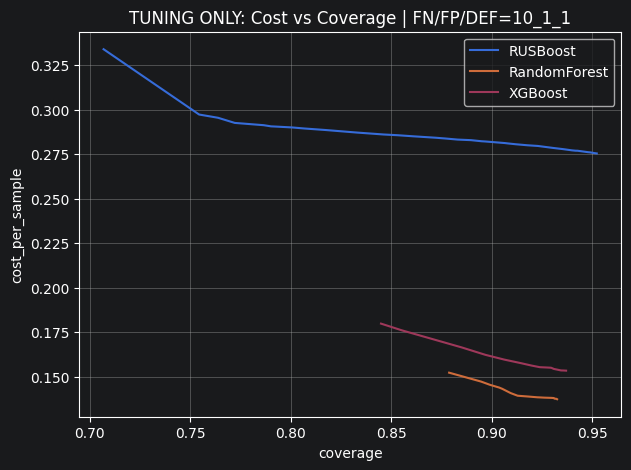

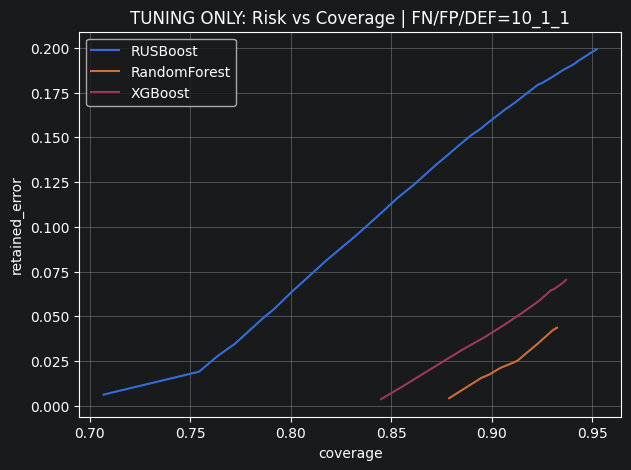

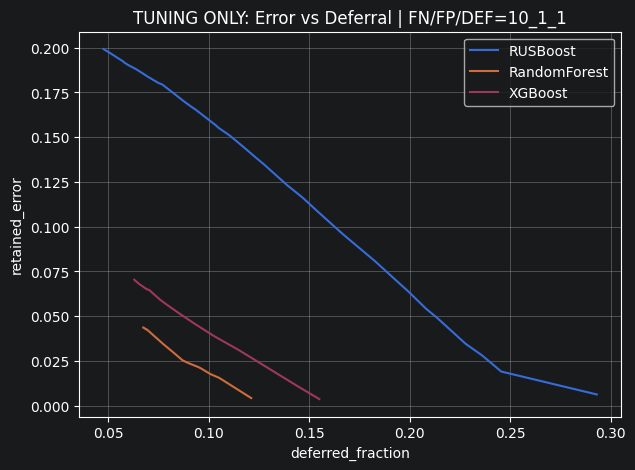

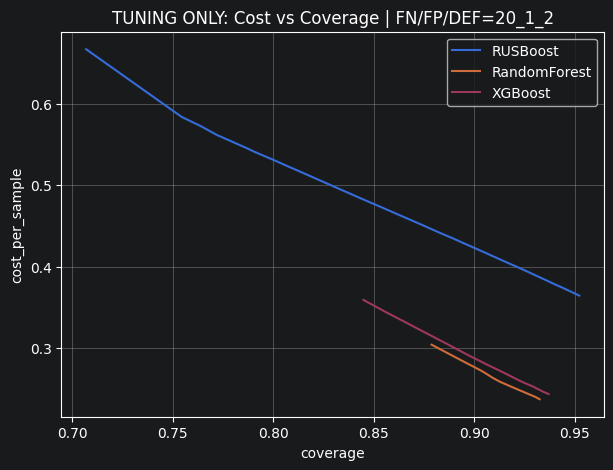

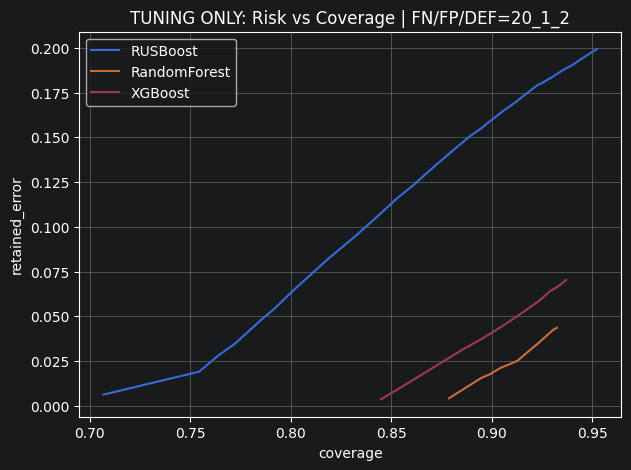

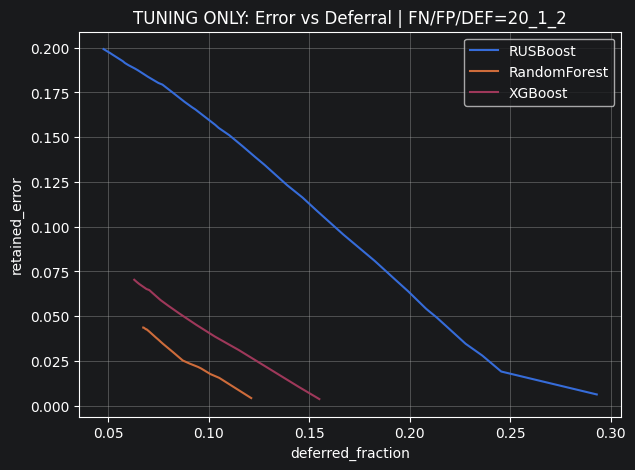

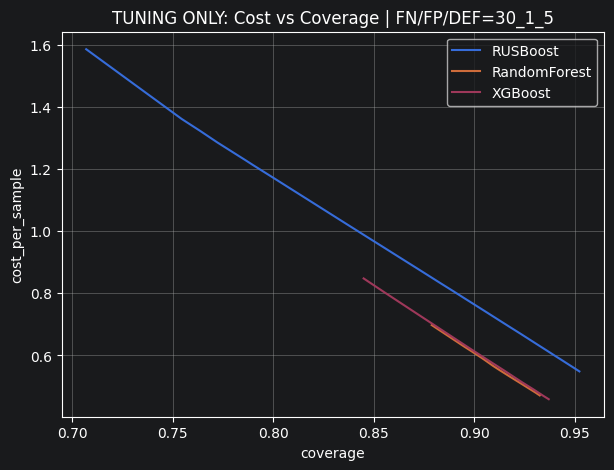

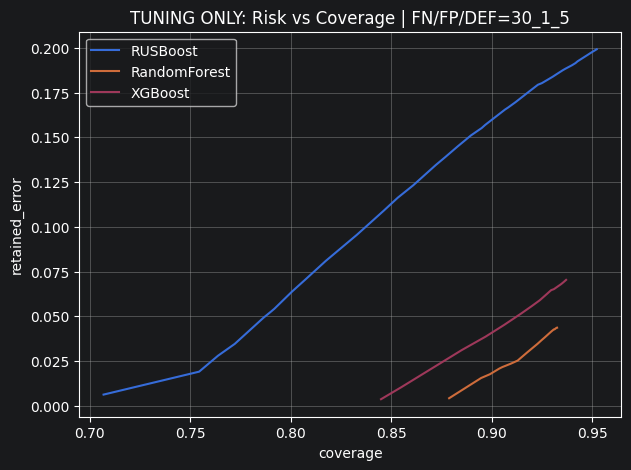

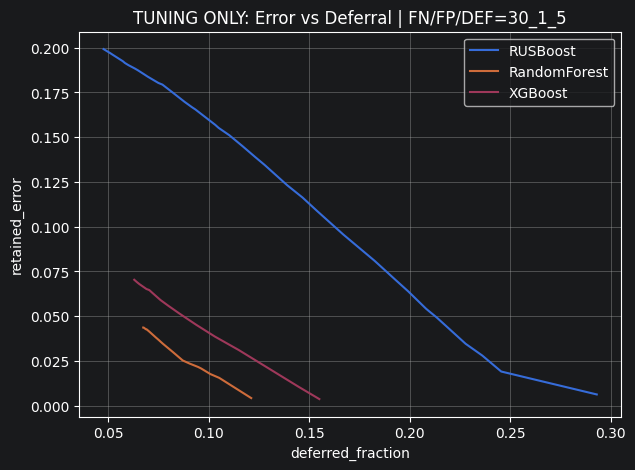

In [11]:
# Curves below are based on the policy-tuning partition, NOT the outer test fold.
mean_curves = all_curves.groupby(['model','cost_scenario','tau'], as_index=False)[
    ['coverage','cost_per_sample','retained_error','deferred_fraction']].mean()
mean_curves.to_csv(RUN_DIR / 'mean_TUNING_ONLY_curves_by_scenario.csv', index=False)
for scenario in sorted(mean_curves['cost_scenario'].unique()):
    sub = mean_curves[mean_curves['cost_scenario'] == scenario]
    for x, y, title in [('coverage','cost_per_sample','Cost vs Coverage'),
                        ('coverage','retained_error','Risk vs Coverage'),
                        ('deferred_fraction','retained_error','Error vs Deferral')]:
        fig, ax = plt.subplots(figsize=(7,5))
        for model, group in sub.groupby('model'):
            ax.plot(group[x], group[y], label=model)
        ax.set(xlabel=x, ylabel=y, title=f'TUNING ONLY: {title} | FN/FP/DEF={scenario}')
        ax.legend(); ax.grid(True)
        fig.savefig(RUN_DIR / f'TUNING_ONLY_{title.replace(" ","_")}_{scenario}.png', dpi=150, bbox_inches='tight')
        plt.show()

## Interpretation guardrails

- `best_cost_per_sample` is **frozen-policy outer-test cost**; `tuning_cost_per_sample` is the **selection criterion**. They must not be conflated.
- `empty_set_fraction`, `singleton_set_fraction`, and `two_label_set_fraction` are distinct, exhaustive categories. An empty set is **not** a two-label ambiguous set.
- `failure_class_coverage` is the observed conditional coverage among failure examples. Standard split conformal guarantees **marginal**, not failure-class coverage; do not claim a class-conditional guarantee.
- The three cost scenarios jointly vary false-negative and deferral costs. Do not attribute their differences solely to false-negative cost.
- No claims about which model wins or improvement over historical results until Step 4 is run and audited.

In [12]:
import numpy as np
import pandas as pd

# Validate the complete repeated-CV experiment
assert len(all_summary) == 450
assert len(all_curves) == 45000

assert all_summary["run_id"].nunique() == 1
assert (all_summary["partition"] == "test").all()
assert (all_curves["partition"] == "policy_tuning").all()

assert all_summary.groupby(
    ["model", "cost_scenario"]
).size().eq(50).all()

set_total = (
    all_summary["empty_set_fraction"]
    + all_summary["singleton_set_fraction"]
    + all_summary["two_label_set_fraction"]
)

assert np.allclose(set_total, 1.0)

calculated_cost = (
    all_summary["C_FN"] * all_summary["fn"]
    + all_summary["C_FP"] * all_summary["fp"]
    + all_summary["C_DEF"] * all_summary["deferred_count"]
) / all_summary["n_test"]

assert np.allclose(
    calculated_cost,
    all_summary["best_cost_per_sample"]
)

print("PASS — 450 frozen-policy test summaries")
print("PASS — 45,000 tuning-only curve records")
print("PASS — 50 folds per model and scenario")
print("PASS — Prediction-set fractions")
print("PASS — Frozen-policy cost accounting")

PASS — 450 frozen-policy test summaries
PASS — 45,000 tuning-only curve records
PASS — 50 folds per model and scenario
PASS — Prediction-set fractions
PASS — Frozen-policy cost accounting


In [13]:
# Primary cost scenario
primary = all_summary[
    all_summary["cost_scenario"] == "20_1_2"
].copy()

diagnostic_metrics = [
    "conformal_coverage",
    "failure_class_coverage",
    "empty_set_fraction",
    "singleton_set_fraction",
    "two_label_set_fraction",
    "best_deferred_fraction",
    "best_retained_recall",
    "best_cost_per_sample",
]

# Finding 1: Conformal coverage by model
print("\n1. CONFORMAL COVERAGE")
print(
    primary.groupby("model")[diagnostic_metrics]
    .agg(["mean", "std"])
    .round(4)
    .to_string()
)

# Finding 2: Empty-set vs deferral behavior
primary["deferral_minus_empty"] = (
    primary["best_deferred_fraction"]
    - primary["empty_set_fraction"]
)

print("\n2. DEFERRAL VS EMPTY SETS")
print(
    primary.groupby("model")[
        "deferral_minus_empty"
    ].agg(["min", "mean", "max"]).round(6)
)

# Finding 3: Selected tau distribution
print("\n3. SELECTED TAU DISTRIBUTION")
print(
    all_summary.groupby(
        ["model", "cost_scenario", "best_tau"]
    ).size().rename("fold_count").to_string()
)

# Count folds with zero failure-class coverage
print("\n4. ZERO FAILURE-CLASS COVERAGE")
print(
    primary.assign(
        zero_failure_coverage=(
            primary["failure_class_coverage"] == 0
        )
    ).groupby("model")[
        "zero_failure_coverage"
    ].sum()
)


1. CONFORMAL COVERAGE
             conformal_coverage         failure_class_coverage         empty_set_fraction         singleton_set_fraction         two_label_set_fraction      best_deferred_fraction         best_retained_recall         best_cost_per_sample        
                           mean     std                   mean     std               mean     std                   mean     std                   mean  std                   mean     std                 mean     std                 mean     std
model                                                                                                                                                                                                                                                
RUSBoost                 0.9324  0.0244                 0.0601  0.0552             0.0468  0.0289                 0.9532  0.0289                    0.0  0.0                 0.0468  0.0289               0.7928  0.0961               0.3685  

In [14]:
from pathlib import Path

# Create a dedicated folder for sharing results
export_dir = Path("Step4_Validation_Results")
export_dir.mkdir(exist_ok=True)

# Export complete evaluation results
all_summary.to_csv(
    export_dir / "all_models_50fold_summary.csv",
    index=False
)

all_curves.to_csv(
    export_dir / "all_models_50fold_tuning_curves.csv",
    index=False
)

print("Results exported successfully!")
print("Location:", export_dir.resolve())

Results exported successfully!
Step4_Validation_Results


In [15]:
import numpy as np
import pandas as pd

keys = ["model", "fold_number", "cost_scenario"]

# Lowest cost and selected policy in each tuning curve
diagnostics = []

for key, group in all_curves.groupby(keys):
    group = group.sort_values("tau")
    base = group.iloc[0]

    min_cost = group["cost_per_sample"].min()
    tied = group[
        np.isclose(group["cost_per_sample"], min_cost)
    ]

    diagnostics.append({
        "model": key[0],
        "fold_number": key[1],
        "cost_scenario": key[2],
        "base_tau": base["tau"],
        "base_cost": base["cost_per_sample"],
        "minimum_cost": min_cost,
        "cost_ties": len(tied),
        "distinct_deferral_rates":
            group["deferred_fraction"].nunique(),
        "maximum_extra_deferral":
            group["deferred_fraction"].max()
            - base["deferred_fraction"],
        "higher_tau_improves_cost":
            bool(min_cost < base["cost_per_sample"] - 1e-10)
    })

tau_diagnostics = pd.DataFrame(diagnostics)

print("Total tuning curves:", len(tau_diagnostics))

print("\nHigher tau improves cost:")
print(
    tau_diagnostics.groupby("model")[
        "higher_tau_improves_cost"
    ].sum()
)

print("\nCost ties and additional deferral:")
print(
    tau_diagnostics.groupby("model")[
        ["cost_ties", "distinct_deferral_rates",
         "maximum_extra_deferral"]
    ].agg(["mean", "min", "max"]).round(4)
)

print("\nCurves with no deferral variation:")
print(
    tau_diagnostics.assign(
        constant_deferral=(
            tau_diagnostics["distinct_deferral_rates"] == 1
        )
    ).groupby("model")["constant_deferral"].sum()
)

Total tuning curves: 450

Higher tau improves cost:
model
RUSBoost        0
RandomForest    0
XGBoost         0
Name: higher_tau_improves_cost, dtype: int64

Cost ties and additional deferral:
             cost_ties          distinct_deferral_rates          \
                  mean min  max                    mean min max   
model                                                             
RUSBoost         76.92  49   94                    3.94   2   7   
RandomForest     95.14  79  100                    1.98   1   5   
XGBoost          95.10  83  100                    2.98   1   7   

             maximum_extra_deferral                
                               mean    min    max  
model                                              
RUSBoost                     0.2455  0.088  0.991  
RandomForest                 0.0537  0.000  0.223  
XGBoost                      0.0921  0.000  0.285  

Curves with no deferral variation:
model
RUSBoost         0
RandomForest    51
XGBoost     

In [16]:
import numpy as np
from repeated_cv.cv_helpers import diagnose_singleton_agreement

# Synthetic probabilities
probs = np.array([
    [0.92, 0.08],
    [0.99, 0.01],
    [0.02, 0.98],
    [0.50, 0.50],
])

# Synthetic conformal prediction sets
cp_sets = [[0], [0], [1], []]

# Run diagnostic
result = diagnose_singleton_agreement(
    probs=probs,
    cp_sets=cp_sets,
    base_threshold=0.05,
    tau=0.50,
)

print(result)

# Validate expected behavior
assert result["n_retained"] == 3
assert result["n_disagreements"] == 1
assert result["predicted_failure_cp_zero"] == 1

print("PASS — Singleton agreement diagnostic")

{'n_observations': 4, 'n_retained': 3, 'n_disagreements': 1, 'disagreement_fraction_all': 0.25, 'disagreement_fraction_retained': 0.3333333333333333, 'predicted_failure_cp_zero': 1, 'predicted_normal_cp_one': 0}
PASS — Singleton agreement diagnostic


In [18]:
from pathlib import Path
import pandas as pd

from repeated_cv.singleton_agreement_diagnostic import (
    diagnose_one_fold
)

# Use your existing model-builder functions:
# build_rf, build_xgb, build_rusboost

BASELINE = Path(
    "Step4_Validation_Results/all_models_50fold_summary.csv"
)

experiments = [
    ("RandomForest", "configs/RandomForest/RFtrain.yaml", build_rf),
    ("XGBoost", "configs/XGBoost/XGtrain.yaml", build_xgb),
    ("RUSBoost", "configs/RUSBoost/RUStrain.yaml", build_rusboost),
]

diagnostic_results = []

for model_name, cfg_path, builder in experiments:
    summary, rows = diagnose_one_fold(
        model_name=model_name,
        cfg_path=cfg_path,
        build_model_fn=builder,
        baseline_csv=BASELINE,
        fold_number=1,
        cost_scenario="20_1_2",
    )

    diagnostic_results.append(summary)

results_df = pd.DataFrame(diagnostic_results)

display(results_df)

,model,fold_number,cost_scenario,baseline_reproduced,n_test,n_retained,n_disagreements,disagreement_fraction_retained,predicted_failure_cp_zero,predicted_normal_cp_one,disagreement_false_positives,disagreement_false_negatives
0,RandomForest,1,20_1_2,True,2000,1927,109,0.056565,109,0,98,0
1,XGBoost,1,20_1_2,True,2000,1893,108,0.057052,108,0,101,0
2,RUSBoost,1,20_1_2,True,2000,1812,286,0.157837,286,0,265,0


In [19]:
from pathlib import Path

# Create a folder for diagnostic outputs
output_dir = Path("Step4_Validation_Results")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the singleton-agreement results
output_file = output_dir / "singleton_agreement_one_fold_results.csv"

results_df.to_csv(output_file, index=False)

print("CSV exported successfully!")
print("File location:", output_file.resolve())

CSV exported successfully!
Step4_Validation_Results/singleton_agreement_one_fold_results.csv


In [20]:
from repeated_cv.full_50fold_singleton_diagnostic import (
    run_full_singleton_diagnostic
)

# Reuse the same experiments list and BASELINE path
# from your successful one-fold diagnostic.

fold_results, model_summary = run_full_singleton_diagnostic(
    experiments=experiments,
    baseline_csv=BASELINE,
    output_dir="Step4_Validation_Results/singleton_50fold",
    cost_scenario="20_1_2",
    n_folds=50,
)

display(model_summary)

RandomForest: fold 1/50 reproduced; disagreements=109
RandomForest: fold 2/50 reproduced; disagreements=104
RandomForest: fold 3/50 reproduced; disagreements=0
RandomForest: fold 4/50 reproduced; disagreements=0
RandomForest: fold 5/50 reproduced; disagreements=0
RandomForest: fold 6/50 reproduced; disagreements=64
RandomForest: fold 7/50 reproduced; disagreements=0
RandomForest: fold 8/50 reproduced; disagreements=0
RandomForest: fold 9/50 reproduced; disagreements=92
RandomForest: fold 10/50 reproduced; disagreements=350
RandomForest: fold 11/50 reproduced; disagreements=300
RandomForest: fold 12/50 reproduced; disagreements=0
RandomForest: fold 13/50 reproduced; disagreements=149
RandomForest: fold 14/50 reproduced; disagreements=106
RandomForest: fold 15/50 reproduced; disagreements=162
RandomForest: fold 16/50 reproduced; disagreements=0
RandomForest: fold 17/50 reproduced; disagreements=0
RandomForest: fold 18/50 reproduced; disagreements=0
RandomForest: fold 19/50 reproduced; di

,model,folds,mean_disagreement_rate,std_disagreement_rate,total_disagreements,disagreement_false_positives,disagreement_true_failures,mean_baseline_cost,mean_singleton_policy_cost,mean_cost_difference
0,RUSBoost,50,0.211097,0.071940,20212,18612,1600,0.36848,0.50236,0.13388
1,RandomForest,50,0.042983,0.054980,4065,3902,163,0.24124,0.23482,-0.00642
2,XGBoost,50,0.068075,0.068912,6409,6184,225,0.25339,0.23655,-0.01684


In [21]:
from pathlib import Path

# Output folder
output_dir = Path("Step4_Validation_Results/singleton_50fold")
output_dir.mkdir(parents=True, exist_ok=True)

# Save detailed results for all 150 model-fold evaluations
fold_results.to_csv(
    output_dir / "singleton_50fold_fold_results.csv",
    index=False
)

# Save the summary table displayed in Jupyter
model_summary.to_csv(
    output_dir / "singleton_50fold_model_summary.csv",
    index=False
)

print("Both CSV files saved successfully!")
print("\nFiles saved to:")

for file in output_dir.glob("*.csv"):
    print(file.resolve())

Both CSV files saved successfully!

Files saved to:
Step4_Validation_Results/singleton_50fold/singleton_50fold_model_summary.csv
Step4_Validation_Results/singleton_50fold/singleton_50fold_PARTIAL.csv
Step4_Validation_Results/singleton_50fold/singleton_50fold_fold_results.csv


In [22]:
from repeated_cv.cost_aware_disagreement_extension import (
    run_disagreement_extension
)

test_results, tuning_results = run_disagreement_extension(
    experiments=experiments,
    baseline_csv=BASELINE,
    output_dir="Step4_Validation_Results/disagreement_extension_smoke",
    fold_numbers=(1,),
    cost_scenarios=("10_1_1", "20_1_2", "30_1_5"),
)

# Check that all baseline reproductions succeeded
assert len(test_results) == 27
assert len(tuning_results) == 27
assert test_results["baseline_reproduced"].all()

# Exactly one selected action per model and cost scenario
assert test_results["is_tuning_selected"].sum() == 9

print("PASS — Step 4.4 one-fold diagnostic")

display(
    test_results[
        test_results["is_tuning_selected"]
    ][[
        "model",
        "cost_scenario",
        "selected_action",
        "baseline_cost_per_sample",
        "cost_per_sample",
        "delta_cost_vs_baseline",
        "fn",
        "fp",
        "deferred_count"
    ]]
)

RandomForest: fold 1 reproduced; disagreement actions evaluated
XGBoost: fold 1 reproduced; disagreement actions evaluated
RUSBoost: fold 1 reproduced; disagreement actions evaluated
PASS — Step 4.4 one-fold diagnostic


,model,cost_scenario,selected_action,baseline_cost_per_sample,cost_per_sample,delta_cost_vs_baseline,fn,fp,deferred_count
1,RandomForest,10_1_1,use_singleton,0.1105,0.1165,0.0060,16,0,73
3,RandomForest,20_1_2,keep_classifier,0.1720,0.1720,0.0000,5,98,73
6,RandomForest,30_1_5,keep_classifier,0.3065,0.3065,0.0000,5,98,73
10,XGBoost,10_1_1,use_singleton,0.1240,0.1085,-0.0155,11,0,107
12,XGBoost,20_1_2,keep_classifier,0.1975,0.1975,0.0000,4,101,107
15,XGBoost,30_1_5,keep_classifier,0.3780,0.3780,0.0000,4,101,107
19,RUSBoost,10_1_1,use_singleton,0.2665,0.2390,-0.0275,29,0,188
21,RUSBoost,20_1_2,keep_classifier,0.4005,0.4005,0.0000,8,265,188
24,RUSBoost,30_1_5,keep_classifier,0.7225,0.7225,0.0000,8,265,188


In [23]:
from repeated_cv.safety_constrained_disagreement_extension import (
    run_safety_constrained_extension
)

safety_test, safety_tuning = run_safety_constrained_extension(
    experiments=experiments,
    baseline_csv=BASELINE,
    output_dir="Step4_Validation_Results/disagreement_safety_smoke",
    fold_numbers=(1,),
    cost_scenarios=("10_1_1", "20_1_2", "30_1_5"),
    recall_targets=(0.80, 0.90),
)

# 3 models × 3 scenarios × 2 recall targets × 3 actions
assert len(safety_test) == 54
assert len(safety_tuning) == 54
assert safety_test["baseline_reproduced"].all()
assert safety_test["is_tuning_selected"].sum() == 18

print("PASS — Step 4.4.2 safety-constrained smoke test")

selected = safety_test[
    safety_test["is_tuning_selected"]
].copy()

display(selected[[
    "model",
    "cost_scenario",
    "recall_target",
    "selected_action",
    "selection_status",
    "retained_recall",
    "detected_failure_fraction",
    "deferred_failure_count",
    "baseline_cost_per_sample",
    "cost_per_sample",
    "delta_cost_vs_baseline"
]])

RandomForest: fold 1 reproduced; disagreement actions evaluated
XGBoost: fold 1 reproduced; disagreement actions evaluated
RUSBoost: fold 1 reproduced; disagreement actions evaluated
PASS — Step 4.4.2 safety-constrained smoke test


,model,cost_scenario,recall_target,selected_action,selection_status,retained_recall,detected_failure_fraction,deferred_failure_count,baseline_cost_per_sample,cost_per_sample,delta_cost_vs_baseline
0,RandomForest,10_1_1,0.8,keep_classifier,feasible,0.857143,0.447761,32,0.1105,0.1105,0.0
3,RandomForest,10_1_1,0.9,keep_classifier,fallback_no_feasible_action,0.857143,0.447761,32,0.1105,0.1105,0.0
6,RandomForest,20_1_2,0.8,keep_classifier,feasible,0.857143,0.447761,32,0.1720,0.1720,0.0
9,RandomForest,20_1_2,0.9,keep_classifier,fallback_no_feasible_action,0.857143,0.447761,32,0.1720,0.1720,0.0
12,RandomForest,30_1_5,0.8,keep_classifier,feasible,0.857143,0.447761,32,0.3065,0.3065,0.0
15,RandomForest,30_1_5,0.9,keep_classifier,fallback_no_feasible_action,0.857143,0.447761,32,0.3065,0.3065,0.0
18,XGBoost,10_1_1,0.8,keep_classifier,feasible,0.870968,0.402985,36,0.1240,0.1240,0.0
21,XGBoost,10_1_1,0.9,keep_classifier,feasible,0.870968,0.402985,36,0.1240,0.1240,0.0
24,XGBoost,20_1_2,0.8,keep_classifier,feasible,0.870968,0.402985,36,0.1975,0.1975,0.0
27,XGBoost,20_1_2,0.9,keep_classifier,feasible,0.870968,0.402985,36,0.1975,0.1975,0.0


In [24]:
from pathlib import Path
from repeated_cv.safety_constrained_disagreement_extension import (
    run_safety_constrained_extension
)

# Use a separate output directory
output_dir = Path(
    "Step4_Validation_Results/disagreement_safety_50fold"
)

# Run all 50 folds for each model
safety_full_test, safety_full_tuning = (
    run_safety_constrained_extension(
        experiments=experiments,
        baseline_csv=BASELINE,
        output_dir=str(output_dir),
        fold_numbers=tuple(range(1, 51)),
        cost_scenarios=(
            "10_1_1",
            "20_1_2",
            "30_1_5"
        ),
        recall_targets=(0.80, 0.90),
    )
)

print("Full evaluation completed.")
print("Test records:", len(safety_full_test))
print("Tuning records:", len(safety_full_tuning))

RandomForest: fold 1 reproduced; disagreement actions evaluated
RandomForest: fold 2 reproduced; disagreement actions evaluated
RandomForest: fold 3 reproduced; disagreement actions evaluated
RandomForest: fold 4 reproduced; disagreement actions evaluated
RandomForest: fold 5 reproduced; disagreement actions evaluated
RandomForest: fold 6 reproduced; disagreement actions evaluated
RandomForest: fold 7 reproduced; disagreement actions evaluated
RandomForest: fold 8 reproduced; disagreement actions evaluated
RandomForest: fold 9 reproduced; disagreement actions evaluated
RandomForest: fold 10 reproduced; disagreement actions evaluated
RandomForest: fold 11 reproduced; disagreement actions evaluated
RandomForest: fold 12 reproduced; disagreement actions evaluated
RandomForest: fold 13 reproduced; disagreement actions evaluated
RandomForest: fold 14 reproduced; disagreement actions evaluated
RandomForest: fold 15 reproduced; disagreement actions evaluated
RandomForest: fold 16 reproduced; 

In [25]:
import pandas as pd

# Validate expected record counts
assert len(safety_full_test) == 2700
assert len(safety_full_tuning) == 2700

# Validate baseline reproduction
assert safety_full_test["baseline_reproduced"].all()

# Validate selected-policy count
selected_full = safety_full_test[
    safety_full_test["is_tuning_selected"]
].copy()

assert len(selected_full) == 900

# Validate each model has 50 folds
assert (
    safety_full_test.groupby("model")["fold_number"]
    .nunique()
    .eq(50)
    .all()
)

print("PASS — Full 50-fold safety-constrained evaluation")

print("\nSelected actions:")
print(
    selected_full.groupby(
        ["model", "recall_target", "selected_action"]
    ).size()
)

print("\nConstraint selection status:")
print(
    selected_full.groupby(
        ["model", "recall_target", "selection_status"]
    ).size()
)

PASS — Full 50-fold safety-constrained evaluation

Selected actions:
model         recall_target  selected_action
RUSBoost      0.8            keep_classifier    150
              0.9            keep_classifier    150
RandomForest  0.8            keep_classifier    150
              0.9            keep_classifier    150
XGBoost       0.8            keep_classifier    144
                             use_singleton        6
              0.9            keep_classifier    150
dtype: int64

Constraint selection status:
model         recall_target  selection_status           
RUSBoost      0.8            fallback_no_feasible_action     57
                             feasible                        93
              0.9            fallback_no_feasible_action    117
                             feasible                        33
RandomForest  0.8            fallback_no_feasible_action     78
                             feasible                        72
              0.9            fallback_

In [26]:
from pathlib import Path

output_dir = Path(
    "Step4_Validation_Results/disagreement_safety_50fold"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Save complete test and tuning results
safety_full_test.to_csv(
    output_dir / "safety_50fold_test_results.csv",
    index=False
)

safety_full_tuning.to_csv(
    output_dir / "safety_50fold_tuning_actions.csv",
    index=False
)

# Save only tuning-selected policies
selected_full.to_csv(
    output_dir / "safety_50fold_selected_policies.csv",
    index=False
)

print("All CSV files saved successfully!")

for filename in [
    "safety_50fold_test_results.csv",
    "safety_50fold_tuning_actions.csv",
    "safety_50fold_selected_policies.csv"
]:
    print((output_dir / filename).resolve())

All CSV files saved successfully!
Step4_Validation_Results/disagreement_safety_50fold/safety_50fold_test_results.csv
Step4_Validation_Results/disagreement_safety_50fold/safety_50fold_tuning_actions.csv
Step4_Validation_Results/disagreement_safety_50fold/safety_50fold_selected_policies.csv
